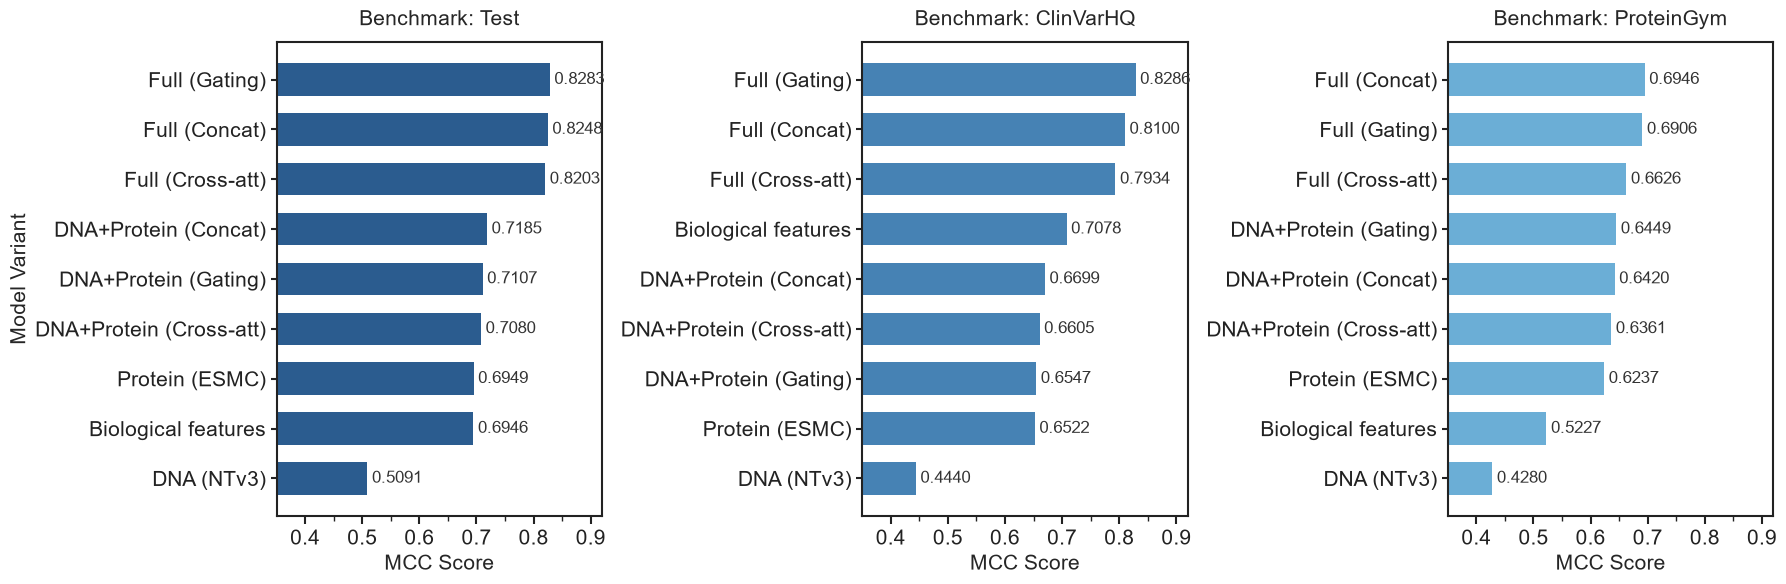

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data = {
    "Model": [
        "DNA (NTv3)",
        "Protein (ESMC)",
        "Biological features",
        "DNA+Protein (Concat)",
        "DNA+Protein (Gating)",
        "DNA+Protein (Cross-att)",
        "Full (Concat)",
        "Full (Gating)",
        "Full (Cross-att)",
    ],
    "Test": [0.5091, 0.6949, 0.6946, 0.7185, 0.7107, 0.7080, 0.8248, 0.8283, 0.8203],
    "ClinVarHQ": [
        0.4440,
        0.6522,
        0.7078,
        0.6699,
        0.6547,
        0.6605,
        0.8100,
        0.8286,
        0.7934,
    ],
    "ProteinGym": [
        0.4280,
        0.6237,
        0.5227,
        0.6420,
        0.6449,
        0.6361,
        0.6946,
        0.6906,
        0.6626,
    ],
}

df = pd.DataFrame(data)

sns.set_theme(style="white", font="sans-serif")
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=False)

eval_sets = ["Test", "ClinVarHQ", "ProteinGym"]
colors = ["#2b5c8f", "#4682b4", "#6baed6"]

# Định nghĩa các mốc vạch chia chính (0.1) và phụ (0.05) trên trục ngang
major_ticks = np.arange(0.4, 0.95, 0.1)
minor_ticks = np.arange(0.4, 0.95, 0.05)

for idx, eval_set in enumerate(eval_sets):
    ax = axes[idx]

    df_sorted = df.sort_values(by=eval_set, ascending=True)

    bars = ax.barh(
        df_sorted["Model"],
        df_sorted[eval_set],
        color=colors[idx],
        edgecolor="none",
        height=0.65,
    )

    # Hiển thị số đo giá trị
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.008,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.4f}",
            va="center",
            ha="left",
            fontsize=12,
            fontweight="normal",
            color="#333333",
        )

    ax.set_title(
        f"Benchmark: {eval_set}", fontsize=15, fontweight="normal", pad=12
    )
    ax.set_xlim(0.35, 0.92)
    ax.set_xlabel("MCC Score", fontweight="normal", fontsize=15)

    # Gắn vị trí các vạch chia
    ax.set_xticks(major_ticks)
    ax.set_xticks(minor_ticks, minor=True)

    # Tùy chỉnh độ dài, độ dày và hiển thị vạch chia trục X & Y
    ax.tick_params(
        axis="x",
        which="major",
        bottom=True,
        length=6,
        width=1.5,
        colors="#222222",
        labelsize=15,
    )
    ax.tick_params(
        axis="x", which="minor", bottom=True, length=3.5, width=1.0, colors="#222222"
    )
    ax.tick_params(axis="y", left=True, length=4, width=1.5, colors="#222222", labelsize=15)

    if idx > 0:
        ax.set_ylabel("")
    else:
        ax.set_ylabel("Model Variant", fontweight="normal", fontsize=15)

    # Tắt đường lưới và làm đậm nét khung
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color("#222222")

plt.tight_layout()
plt.savefig(r"C:\Users\dotru\STUDIE\FPTU\AiTA_Lab\Missense_variant_pathogenicity_prediction\visualization\capstone_visualization\5_1_modalities_ablation.png", dpi=400, bbox_inches="tight")
plt.show()

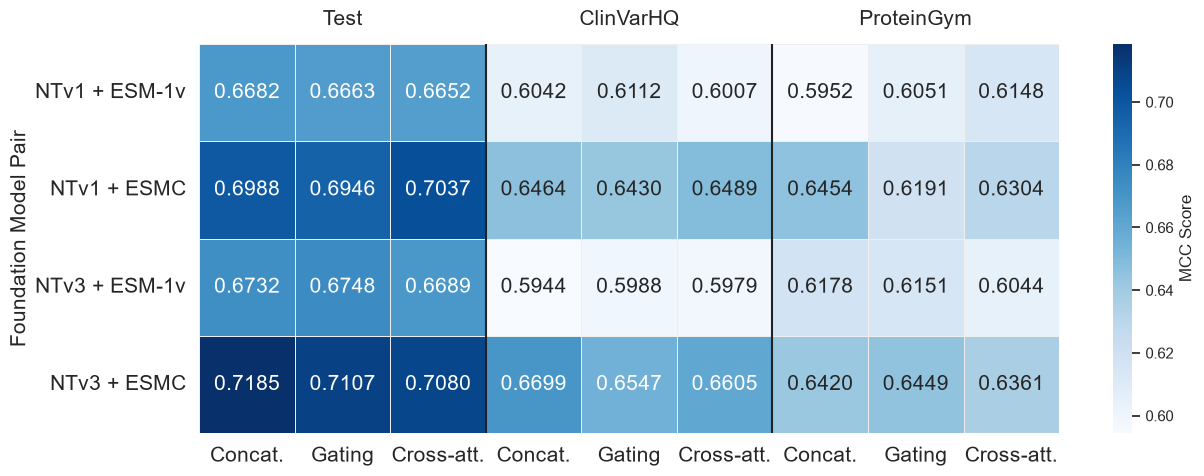

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Khởi tạo dữ liệu
pairs = ["NTv1 + ESM-1v", "NTv1 + ESMC", "NTv3 + ESM-1v", "NTv3 + ESMC"]

columns = [
    "Concat.",
    "Gating",
    "Cross-att.",
    "Concat.",
    "Gating",
    "Cross-att.",
    "Concat.",
    "Gating",
    "Cross-att.",
]

data = np.array(
    [
        [0.6682, 0.6663, 0.6652, 0.6042, 0.6112, 0.6007, 0.5952, 0.6051, 0.6148],
        [0.6988, 0.6946, 0.7037, 0.6464, 0.6430, 0.6489, 0.6454, 0.6191, 0.6304],
        [0.6732, 0.6748, 0.6689, 0.5944, 0.5988, 0.5979, 0.6178, 0.6151, 0.6044],
        [0.7185, 0.7107, 0.7080, 0.6699, 0.6547, 0.6605, 0.6420, 0.6449, 0.6361],
    ]
)

# 2. Cấu hình theme trắng không đường lưới
sns.set_theme(style="white", font="sans-serif")
fig, ax = plt.subplots(figsize=(13, 5))

# 3. Vẽ Heatmap
sns.heatmap(
    data,
    annot=True,
    fmt=".4f",
    cmap="Blues",
    xticklabels=columns,
    yticklabels=pairs,
    cbar_kws={"label": "MCC Score"},
    linewidths=0.5,
    linecolor="#eeeeee",
    ax=ax,
    annot_kws={"size": 15, "weight": "normal"},
)

# 4. Thêm nhãn nhóm cho 3 tập dữ liệu ở phía trên
ax.text(
    1.5,
    -0.25,
    "Test",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="normal",
    transform=ax.transData,
)
ax.text(
    4.5,
    -0.25,
    "ClinVarHQ",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="normal",
    transform=ax.transData,
)
ax.text(
    7.5,
    -0.25,
    "ProteinGym",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="normal",
    transform=ax.transData,
)

# 5. Vẽ vạch phân cách giữa 3 tập dữ liệu
ax.axvline(3, color="#222222", linewidth=1.5)
ax.axvline(6, color="#222222", linewidth=1.5)

# 6. Định dạng nhãn và khung
ax.set_ylabel("Foundation Model Pair", fontsize=15, fontweight="normal")
ax.tick_params(axis="x", rotation=0, labelsize=15)
ax.tick_params(axis="y", rotation=0, labelsize=15)

# Đậm viền khung bên ngoài
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("#222222")

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.savefig(r"C:\Users\dotru\STUDIE\FPTU\AiTA_Lab\Missense_variant_pathogenicity_prediction\visualization\capstone_visualization\5_2_heatmap_pairs.png", dpi=300, bbox_inches="tight")
plt.show()

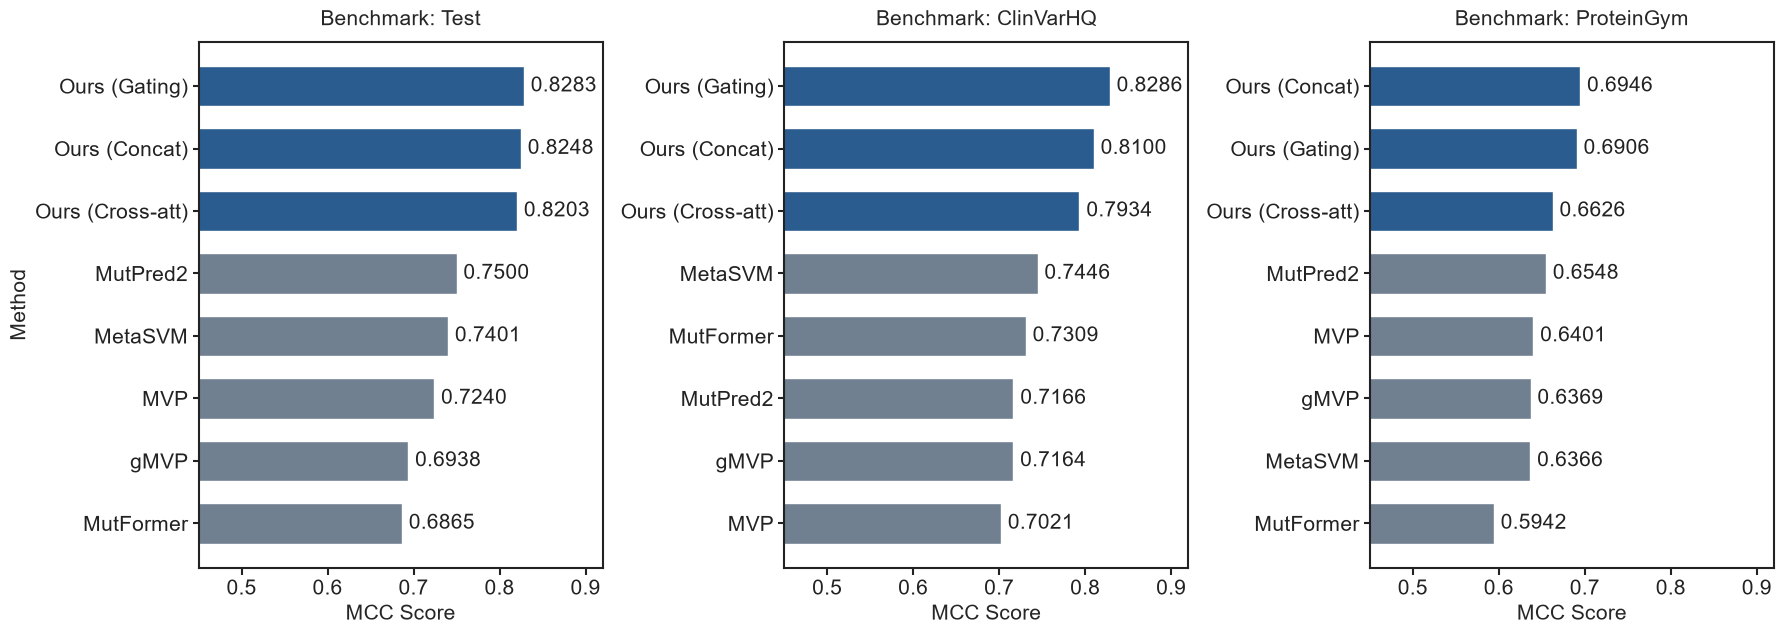

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

data = {
    'Method': ['MVP', 'gMVP', 'MetaSVM', 'MutFormer', 'MutPred2', 
               'Ours (Concat)', 'Ours (Gating)', 'Ours (Cross-att)'],
    'Type': ['Baseline']*5 + ['Ours']*3,
    'Test_MCC': [0.7240, 0.6938, 0.7401, 0.6865, 0.7500, 0.8248, 0.8283, 0.8203],
    'ClinVarHQ_MCC': [0.7021, 0.7164, 0.7446, 0.7309, 0.7166, 0.8100, 0.8286, 0.7934],
    'ProteinGym_MCC': [0.6401, 0.6369, 0.6366, 0.5942, 0.6548, 0.6946, 0.6906, 0.6626]
}

df = pd.DataFrame(data)

sns.set_theme(style="white", font="sans-serif")
fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), sharex=False)

eval_sets = ['Test', 'ClinVarHQ', 'ProteinGym']
major_ticks = np.arange(0.5, 0.95, 0.1)

for idx, eval_set in enumerate(eval_sets):
    ax = axes[idx]
    col_name = f'{eval_set}_MCC'
    df_sorted = df.sort_values(by=col_name, ascending=True)
    
    # Phân biệt màu giữa SOTA (Xám) và Ours (Xanh)
    colors = ['#708090' if t == 'Baseline' else '#2b5c8f' for t in df_sorted['Type']]
    
    bars = ax.barh(df_sorted['Method'], df_sorted[col_name], color=colors, height=0.65)
    
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.008, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
                va='center', ha='left', fontsize=15, fontweight='normal', color='#222222')
        
    ax.set_title(f'Benchmark: {eval_set}', fontsize=15, fontweight='normal', pad=12)
    ax.set_xlim(0.45, 0.92)
    ax.set_xlabel('MCC Score', fontweight='normal', fontsize=15)
    ax.set_xticks(major_ticks)
    
    ax.tick_params(axis='x', which='major', bottom=True, length=5, width=1.5, colors='#222222', labelsize=15)
    ax.tick_params(axis='y', left=True, length=4, width=1.5, colors='#222222', labelsize=15)
    
    if idx > 0:
        ax.set_ylabel('')
    else:
        ax.set_ylabel('Method', fontweight='normal', fontsize=15)
        
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('#222222')

plt.tight_layout()
plt.savefig(r"C:\Users\dotru\STUDIE\FPTU\AiTA_Lab\Missense_variant_pathogenicity_prediction\visualization\capstone_visualization\5_3_sota_compare.png", dpi=300, bbox_inches='tight')
plt.show()